This jupyter notebook is adapted from https://www.nltk.org/book/ch05.html

# 1   Using a Tagger
A part-of-speech tagger, or POS-tagger, processes a sequence of words, and attaches a part of speech tag to each word

In [1]:
import nltk

In [2]:
from nltk.tokenize import word_tokenize

In [3]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [4]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [5]:
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [6]:
text = word_tokenize("And now for something completely different")

In [7]:
text

['And', 'now', 'for', 'something', 'completely', 'different']

In [8]:
nltk.pos_tag(text)

[('And', 'CC'),
 ('now', 'RB'),
 ('for', 'IN'),
 ('something', 'NN'),
 ('completely', 'RB'),
 ('different', 'JJ')]

Here we see that and is CC, a coordinating conjunction; now and completely are RB, or adverbs; for is IN, a preposition; something is NN, a noun; and different is JJ, an adjective.

Let's look at another example, this time including some homonyms:

In [9]:
text = word_tokenize("They refuse to permit us to obtain the refuse permit")

In [10]:
nltk.pos_tag(text)

[('They', 'PRP'),
 ('refuse', 'VBP'),
 ('to', 'TO'),
 ('permit', 'VB'),
 ('us', 'PRP'),
 ('to', 'TO'),
 ('obtain', 'VB'),
 ('the', 'DT'),
 ('refuse', 'NN'),
 ('permit', 'NN')]

Notice that refuse and permit both appear as a present tense verb (VBP) and a noun (NN). E.g. refUSE is a verb meaning "deny," while REFuse is a noun meaning "trash" (i.e. they are not homophones). Thus, we need to know which word is being used in order to pronounce the text correctly. (For this reason, text-to-speech systems usually perform POS-tagging.)

In [11]:
text = word_tokenize("They wind back the clock, while we chase after the wind. ")

In [12]:
nltk.pos_tag(text)

[('They', 'PRP'),
 ('wind', 'VBP'),
 ('back', 'RB'),
 ('the', 'DT'),
 ('clock', 'NN'),
 (',', ','),
 ('while', 'IN'),
 ('we', 'PRP'),
 ('chase', 'VBP'),
 ('after', 'IN'),
 ('the', 'DT'),
 ('wind', 'NN'),
 ('.', '.')]

# 2 Building a Tagger
Now we will explore various ways to automatically add part-of-speech tags to text. We will see that the tag of a word depends on the word and its context within a sentence. For this reason, we will be working with data at the level of (tagged) sentences rather than words. We'll begin by loading the data we will be using.

In [13]:
nltk.download('brown')

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


True

In [14]:
from nltk.corpus import brown

In [15]:
len(brown.words())

1161192

In [16]:
brown.words()[:10]

['The',
 'Fulton',
 'County',
 'Grand',
 'Jury',
 'said',
 'Friday',
 'an',
 'investigation',
 'of']

In [17]:
brown_tagged_sents = brown.tagged_sents(categories='news')
# This line gets the Brown Corpus’s “news” section,
# with each sentence already tagged with part of speech,
# and stores it in brown_tagged_sents.

In [18]:
brown_tagged_sents

[[('The', 'AT'), ('Fulton', 'NP-TL'), ('County', 'NN-TL'), ('Grand', 'JJ-TL'), ('Jury', 'NN-TL'), ('said', 'VBD'), ('Friday', 'NR'), ('an', 'AT'), ('investigation', 'NN'), ('of', 'IN'), ("Atlanta's", 'NP$'), ('recent', 'JJ'), ('primary', 'NN'), ('election', 'NN'), ('produced', 'VBD'), ('``', '``'), ('no', 'AT'), ('evidence', 'NN'), ("''", "''"), ('that', 'CS'), ('any', 'DTI'), ('irregularities', 'NNS'), ('took', 'VBD'), ('place', 'NN'), ('.', '.')], [('The', 'AT'), ('jury', 'NN'), ('further', 'RBR'), ('said', 'VBD'), ('in', 'IN'), ('term-end', 'NN'), ('presentments', 'NNS'), ('that', 'CS'), ('the', 'AT'), ('City', 'NN-TL'), ('Executive', 'JJ-TL'), ('Committee', 'NN-TL'), (',', ','), ('which', 'WDT'), ('had', 'HVD'), ('over-all', 'JJ'), ('charge', 'NN'), ('of', 'IN'), ('the', 'AT'), ('election', 'NN'), (',', ','), ('``', '``'), ('deserves', 'VBZ'), ('the', 'AT'), ('praise', 'NN'), ('and', 'CC'), ('thanks', 'NNS'), ('of', 'IN'), ('the', 'AT'), ('City', 'NN-TL'), ('of', 'IN-TL'), ('Atlant

In [19]:
brown_sents = brown.sents(categories='news')

In [20]:
brown_sents

[['The', 'Fulton', 'County', 'Grand', 'Jury', 'said', 'Friday', 'an', 'investigation', 'of', "Atlanta's", 'recent', 'primary', 'election', 'produced', '``', 'no', 'evidence', "''", 'that', 'any', 'irregularities', 'took', 'place', '.'], ['The', 'jury', 'further', 'said', 'in', 'term-end', 'presentments', 'that', 'the', 'City', 'Executive', 'Committee', ',', 'which', 'had', 'over-all', 'charge', 'of', 'the', 'election', ',', '``', 'deserves', 'the', 'praise', 'and', 'thanks', 'of', 'the', 'City', 'of', 'Atlanta', "''", 'for', 'the', 'manner', 'in', 'which', 'the', 'election', 'was', 'conducted', '.'], ...]

##   The Default Tagger
The simplest possible tagger assigns the same tag to each token. This may seem to be a rather banal step, but it establishes an important baseline for tagger performance. In order to get the best result, we tag each word with the most likely tag. Let's find out which tag is most likely (now using the unsimplified tagset):

In [21]:
tags = [tag for (word, tag) in brown.tagged_words(categories='news')]

In [22]:
nltk.FreqDist(tags).max()

'NN'

In [23]:
raw = 'I do not like green eggs and ham, I do not like them Sam I am!'
tokens = nltk.word_tokenize(raw)
default_tagger = nltk.DefaultTagger('NN')
default_tagger.tag(tokens)

[('I', 'NN'),
 ('do', 'NN'),
 ('not', 'NN'),
 ('like', 'NN'),
 ('green', 'NN'),
 ('eggs', 'NN'),
 ('and', 'NN'),
 ('ham', 'NN'),
 (',', 'NN'),
 ('I', 'NN'),
 ('do', 'NN'),
 ('not', 'NN'),
 ('like', 'NN'),
 ('them', 'NN'),
 ('Sam', 'NN'),
 ('I', 'NN'),
 ('am', 'NN'),
 ('!', 'NN')]

Unsurprisingly, this method performs rather poorly. On a typical corpus, it will tag only about an eighth of the tokens correctly, as we see below:

In [24]:
default_tagger.accuracy(brown_tagged_sents)

0.13089484257215028

## The Regular Expression Tagger

The regular expression tagger assigns tags to tokens on the basis of matching patterns. For instance, we might guess that any word ending in ed is the past participle of a verb, and any word ending with 's is a possessive noun. We can express these as a list of regular expressions:

In [25]:
patterns = [
     (r'.*ing$', 'VBG'),                # gerunds
     (r'.*ed$', 'VBD'),                 # simple past
     (r'.*es$', 'VBZ'),                 # 3rd singular present
     (r'.*\'s$', 'NN$'),                # possessive nouns
     (r'.*s$', 'NNS'),                  # plural nouns
     (r'^-?[0-9]+(\.[0-9]+)?$', 'CD'),  # cardinal numbers
     (r'.*', 'NN')                      # nouns (default)


 ]

Note that these are processed in order, and the first one that matches is applied. Now we can set up a tagger and use it to tag a sentence. Now its right about a fifth of the time.

In [26]:
regexp_tagger = nltk.RegexpTagger(patterns)

In [27]:
regexp_tagger.tag(brown_sents[3])

[('``', 'NN'),
 ('Only', 'NN'),
 ('a', 'NN'),
 ('relative', 'NN'),
 ('handful', 'NN'),
 ('of', 'NN'),
 ('such', 'NN'),
 ('reports', 'NNS'),
 ('was', 'NNS'),
 ('received', 'VBD'),
 ("''", 'NN'),
 (',', 'NN'),
 ('the', 'NN'),
 ('jury', 'NN'),
 ('said', 'NN'),
 (',', 'NN'),
 ('``', 'NN'),
 ('considering', 'VBG'),
 ('the', 'NN'),
 ('widespread', 'NN'),
 ('interest', 'NN'),
 ('in', 'NN'),
 ('the', 'NN'),
 ('election', 'NN'),
 (',', 'NN'),
 ('the', 'NN'),
 ('number', 'NN'),
 ('of', 'NN'),
 ('voters', 'NNS'),
 ('and', 'NN'),
 ('the', 'NN'),
 ('size', 'NN'),
 ('of', 'NN'),
 ('this', 'NNS'),
 ('city', 'NN'),
 ("''", 'NN'),
 ('.', 'NN')]

In [28]:
regexp_tagger.accuracy(brown_tagged_sents)

0.19797322831513417

# YOUR TURN

Revise the regular expression pattern and add the following patterns:

modify the pattern, adding a few patterns:
- assign anything ending with ly to an adverb (RB)
- assign anything ending with ous to an adjective (JJ)
- assign anything ending with able to an adjective (JJ)
- assign anything ending with less to an adjective (JJ)
- assign anything ending with ment to a noun (NN)
- assign anything ending with tion to a noun (NN)
- assign anything ending with ity to a noun (NN)
- assign anything ending with ould to a modal (MD)
What is your revised pattern?
What is the new accuracy you get with the revised pattern?

In [52]:
# Define the updated regular expression patterns with the new rules
revised_patterns = [
    (r'.*ing$', 'VBG'),
    (r'.*ed$', 'VBD'),
    (r'.*es$', 'VBZ'),
    (r'.*\'s$', 'NN$'),
    (r'.*s$', 'NNS'),
    (r'^-?[0-9]+(\.[0-9]+)?$', 'CD'),
    (r'.*ly$', 'RB'),
    (r'.*ous$', 'JJ'),
    (r'.*able$', 'JJ'),
    (r'.*less$', 'JJ'),
    (r'.*ment$', 'NN'),
    (r'.*tion$', 'NN'),
    (r'.*ity$', 'NN'),
    (r'.*ould$', 'MD'),
    (r'.*', 'NN')
]

# Instantiate the updated tagger
revised_regexp_tagger = nltk.RegexpTagger(revised_patterns)

# Print the revised patterns
print("Revised Patterns:")
for pattern in revised_patterns:
    print(f"  {pattern}")

# Evaluate and display the new accuracy
new_accuracy = revised_regexp_tagger.accuracy(brown_tagged_sents)
print(f"\nNew Accuracy: {new_accuracy:.5f}")

Revised Patterns:
  ('.*ing$', 'VBG')
  ('.*ed$', 'VBD')
  ('.*es$', 'VBZ')
  (".*\\'s$", 'NN$')
  ('.*s$', 'NNS')
  ('^-?[0-9]+(\\.[0-9]+)?$', 'CD')
  ('.*ly$', 'RB')
  ('.*ous$', 'JJ')
  ('.*able$', 'JJ')
  ('.*less$', 'JJ')
  ('.*ment$', 'NN')
  ('.*tion$', 'NN')
  ('.*ity$', 'NN')
  ('.*ould$', 'MD')
  ('.*', 'NN')

New Accuracy: 0.20929


# The Lookup Tagger

A lot of high-frequency words do not have the NN tag. Let's find the hundred most frequent words and store their most likely tag. We can then use this information as the model for a "lookup tagger" (an NLTK UnigramTagger)

In [29]:
fd = nltk.FreqDist(brown.words(categories='news'))

In [30]:
cfd = nltk.ConditionalFreqDist(brown.tagged_words(categories='news'))

In [31]:
most_freq_words = fd.most_common(100)

In [32]:
most_freq_words[:5]

[('the', 5580), (',', 5188), ('.', 4030), ('of', 2849), ('and', 2146)]

In [33]:
likely_tags = dict((word, cfd[word].max()) for (word, _) in most_freq_words)

In [34]:
list(likely_tags.items())[:5]

[('the', 'AT'), (',', ','), ('.', '.'), ('of', 'IN'), ('and', 'CC')]

In [35]:
baseline_tagger = nltk.UnigramTagger(model=likely_tags)

In [36]:
baseline_tagger.accuracy(brown_tagged_sents)

0.45578495136941344

It should come as no surprise by now that simply knowing the tags for the 100 most frequent words enables us to tag a large fraction of tokens correctly (nearly half in fact). Let's see what it does on some untagged input text:

In [37]:
sent = brown.sents(categories='news')[3]
baseline_tagger.tag(sent)

[('``', '``'),
 ('Only', None),
 ('a', 'AT'),
 ('relative', None),
 ('handful', None),
 ('of', 'IN'),
 ('such', None),
 ('reports', None),
 ('was', 'BEDZ'),
 ('received', None),
 ("''", "''"),
 (',', ','),
 ('the', 'AT'),
 ('jury', None),
 ('said', 'VBD'),
 (',', ','),
 ('``', '``'),
 ('considering', None),
 ('the', 'AT'),
 ('widespread', None),
 ('interest', None),
 ('in', 'IN'),
 ('the', 'AT'),
 ('election', None),
 (',', ','),
 ('the', 'AT'),
 ('number', None),
 ('of', 'IN'),
 ('voters', None),
 ('and', 'CC'),
 ('the', 'AT'),
 ('size', None),
 ('of', 'IN'),
 ('this', 'DT'),
 ('city', None),
 ("''", "''"),
 ('.', '.')]

Many words have been assigned a tag of None, because they were not among the 100 most frequent words. In these cases we would like to assign the default tag of NN. In other words, we want to use the lookup table first, and if it is unable to assign a tag, then use the default tagger, a process known as backoff (5). We do this by specifying one tagger as a parameter to the other, as shown below. Now the lookup tagger will only store word-tag pairs for words other than nouns, and whenever it cannot assign a tag to a word it will invoke the default tagger.

In [38]:
baseline_tagger = nltk.UnigramTagger(model=likely_tags,
                                      backoff=nltk.DefaultTagger('NN'))

In [39]:
baseline_tagger.accuracy(brown_tagged_sents)

0.5817769556656125

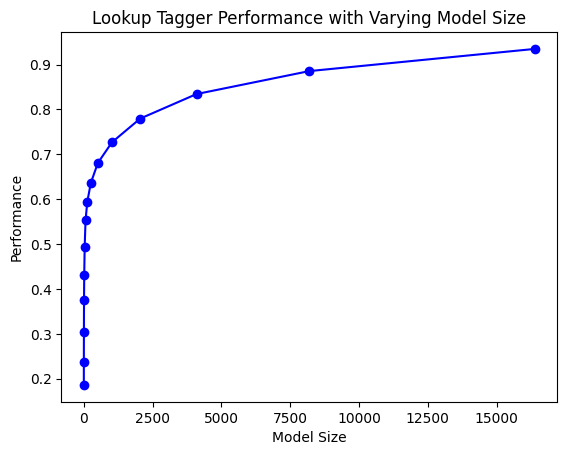

In [40]:
# This code tests how the lookup tagger’s accuracy changes as its dictionary grows.
# It maps each word to its most frequent tag in the Brown Corpus news category.
# Words missing from the dictionary are tagged as nouns (`NN`).
# The tagger is evaluated on the news sentences for each dictionary size.
# The plot shows accuracy for dictionaries of 1, 2, 4, 8, all the way to 2^{14}.

def performance(cfd, wordlist):
    lt = dict((word, cfd[word].max()) for word in wordlist)
    baseline_tagger = nltk.UnigramTagger(model=lt, backoff=nltk.DefaultTagger('NN'))
    return baseline_tagger.accuracy(brown.tagged_sents(categories='news'))

def display():
    import pylab
    word_freqs = nltk.FreqDist(brown.words(categories='news')).most_common()
    words_by_freq = [w for (w, _) in word_freqs]
    cfd = nltk.ConditionalFreqDist(brown.tagged_words(categories='news'))
    sizes = 2 ** pylab.arange(15)
    perfs = [performance(cfd, words_by_freq[:size]) for size in sizes]
    pylab.plot(sizes, perfs, '-bo')
    pylab.title('Lookup Tagger Performance with Varying Model Size')
    pylab.xlabel('Model Size')
    pylab.ylabel('Performance')
    pylab.show()

display()

# 3 N-gram tagging
## Unigram tagging
Unigram taggers are based on a simple statistical algorithm: for each token, assign the tag that is most likely for that particular token. For example, it will assign the tag JJ to any occurrence of the word frequent, since frequent is used as an adjective (e.g. a frequent word) more often than it is used as a verb (e.g. I frequent this cafe). A unigram tagger behaves just like a lookup tagger (4), except there is a more convenient technique for setting it up, called training. In the following code sample, we train a unigram tagger, use it to tag a sentence, then evaluate:

In [41]:
from nltk.corpus import brown
brown_tagged_sents = brown.tagged_sents(categories='news')
brown_sents = brown.sents(categories='news')
unigram_tagger = nltk.UnigramTagger(brown_tagged_sents)
unigram_tagger.tag(brown_sents[2007])

[('Various', 'JJ'),
 ('of', 'IN'),
 ('the', 'AT'),
 ('apartments', 'NNS'),
 ('are', 'BER'),
 ('of', 'IN'),
 ('the', 'AT'),
 ('terrace', 'NN'),
 ('type', 'NN'),
 (',', ','),
 ('being', 'BEG'),
 ('on', 'IN'),
 ('the', 'AT'),
 ('ground', 'NN'),
 ('floor', 'NN'),
 ('so', 'QL'),
 ('that', 'CS'),
 ('entrance', 'NN'),
 ('is', 'BEZ'),
 ('direct', 'JJ'),
 ('.', '.')]

In [42]:
unigram_tagger.evaluate(brown_tagged_sents)

/tmp/ipykernel_2039/1449911821.py:1: DeprecationWarning: 
  Function evaluate() has been deprecated.  Use accuracy(gold)
  instead.
  unigram_tagger.evaluate(brown_tagged_sents)


0.9349006503968017

We train a UnigramTagger by specifying tagged sentence data as a parameter when we initialize the tagger. The training process involves inspecting the tag of each word and storing the most likely tag for any word in a dictionary, stored inside the tagger.



##  Separating the Training and Testing Data
Now that we are training a tagger on some data, we must be careful not to test it on the same data, as we did in the above example. A tagger that simply memorized its training data and made no attempt to construct a general model would get a perfect score, but would also be useless for tagging new text. Instead, we should split the data, training on 90% and testing on the remaining 10%:

In [43]:
size = int(len(brown_tagged_sents) * 0.9)
size

4160

In [44]:
train_sents = brown_tagged_sents[:size]
test_sents = brown_tagged_sents[size:]
unigram_tagger = nltk.UnigramTagger(train_sents)
unigram_tagger.evaluate(test_sents)

/tmp/ipykernel_2039/1988371040.py:4: DeprecationWarning: 
  Function evaluate() has been deprecated.  Use accuracy(gold)
  instead.
  unigram_tagger.evaluate(test_sents)


0.8121200039868434

Although the score is worse, we now have a better picture of the usefulness of this tagger, i.e. its performance on previously unseen text.

##  General N-Gram Tagging
When we perform a language processing task based on unigrams, we are using one item of context. In the case of tagging, we only consider the current token, in isolation from any larger context. Given such a model, the best we can do is tag each word with its a priori most likely tag. This means we would tag a word such as wind with the same tag, regardless of whether it appears in the context the wind or to wind.

The NgramTagger class uses a tagged training corpus to determine which part-of-speech tag is most likely for each context. Here we see a special case of an n-gram tagger, namely a bigram tagger. First we train it, then use it to tag untagged sentences:

For a bigram tagger, the context for the current word is the previous word’s POS tag. During training, it learns which tag most often followed each previous tag. For example, after a determiner tag, a noun tag might be common.

A trigram tagger uses the two previous POS tags as context.

In [45]:
bigram_tagger = nltk.BigramTagger(train_sents)

In [46]:
bigram_tagger.tag(brown_sents[2007])

[('Various', 'JJ'),
 ('of', 'IN'),
 ('the', 'AT'),
 ('apartments', 'NNS'),
 ('are', 'BER'),
 ('of', 'IN'),
 ('the', 'AT'),
 ('terrace', 'NN'),
 ('type', 'NN'),
 (',', ','),
 ('being', 'BEG'),
 ('on', 'IN'),
 ('the', 'AT'),
 ('ground', 'NN'),
 ('floor', 'NN'),
 ('so', 'CS'),
 ('that', 'CS'),
 ('entrance', 'NN'),
 ('is', 'BEZ'),
 ('direct', 'JJ'),
 ('.', '.')]

In [47]:
unseen_sent = brown_sents[4203]

In [48]:
bigram_tagger.tag(unseen_sent)

[('The', 'AT'),
 ('population', 'NN'),
 ('of', 'IN'),
 ('the', 'AT'),
 ('Congo', 'NP'),
 ('is', 'BEZ'),
 ('13.5', None),
 ('million', None),
 (',', None),
 ('divided', None),
 ('into', None),
 ('at', None),
 ('least', None),
 ('seven', None),
 ('major', None),
 ('``', None),
 ('culture', None),
 ('clusters', None),
 ("''", None),
 ('and', None),
 ('innumerable', None),
 ('tribes', None),
 ('speaking', None),
 ('400', None),
 ('separate', None),
 ('dialects', None),
 ('.', None)]

Notice that the bigram tagger manages to tag every word in a sentence it saw during training, but does badly on an unseen sentence. As soon as it encounters a new word (i.e., 13.5), it is unable to assign a tag. It cannot tag the following word (i.e., million) even if it was seen during training, simply because it never saw it during training with a None tag on the previous word. Consequently, the tagger fails to tag the rest of the sentence. Its overall accuracy score is very low:

In [49]:
bigram_tagger.evaluate(test_sents)

/tmp/ipykernel_2039/705572540.py:1: DeprecationWarning: 
  Function evaluate() has been deprecated.  Use accuracy(gold)
  instead.
  bigram_tagger.evaluate(test_sents)


0.10206319146815508

As n gets larger, the specificity of the contexts increases, as does the chance that the data we wish to tag contains contexts that were not present in the training data. This is known as the sparse data problem, and is quite pervasive in NLP. As a consequence, there is a trade-off between the accuracy and the coverage of our results (and this is related to the precision/recall trade-off in information retrieval).

## Combining Taggers
One way to address the trade-off between accuracy and coverage is to use the more accurate algorithms when we can, but to fall back on algorithms with wider coverage when necessary. For example, we could combine the results of a bigram tagger, a unigram tagger, and a default tagger, as follows:

Try tagging the token with the bigram tagger.
If the bigram tagger is unable to find a tag for the token, try the unigram tagger.
If the unigram tagger is also unable to find a tag, use a default tagger.
Most NLTK taggers permit a backoff-tagger to be specified. The backoff-tagger may itself have a backoff tagger:

In [50]:
t0 = nltk.DefaultTagger('NN')
t1 = nltk.UnigramTagger(train_sents, backoff=t0)
t2 = nltk.BigramTagger(train_sents, backoff=t1)
t2.evaluate(test_sents)

/tmp/ipykernel_2039/2463049084.py:4: DeprecationWarning: 
  Function evaluate() has been deprecated.  Use accuracy(gold)
  instead.
  t2.evaluate(test_sents)


0.8452108043456593

Note that we specify the backoff tagger when the tagger is initialized so that training can take advantage of the backoff tagger. Thus, if the bigram tagger would assign the same tag as its unigram backoff tagger in a certain context, the bigram tagger discards the training instance. This keeps the bigram tagger model as small as possible. We can further specify that a tagger needs to see more than one instance of a context in order to retain it, e.g. nltk.BigramTagger(sents, cutoff=2, backoff=t1) will discard contexts that have only been seen once or twice.